### 为什么选择多智能体

单Agent的特点 - 当兵作战（LangChain内置）
- 结构简单，只有一个智能体负责所有任务
- 决策过程集中，不需要协调多个Agent之间的通信
- 适合处理相对简单或专一的任务
- 通常计算资源需求较少
- 响应速度可能更快，因为不需要多Agent间的协调

多Agents的特点 - 三个臭皮匠（LangGraph内置）
- 系统由多个相互协作的智能体组成
- 各Agent可能有不同的专业领域或功能
- 需要Agent之间的通信和协调机制
- 可以并行处理多个任务
- 系统整体更加复杂但也更加强大
- 具有更好的可扩展性和容错能力

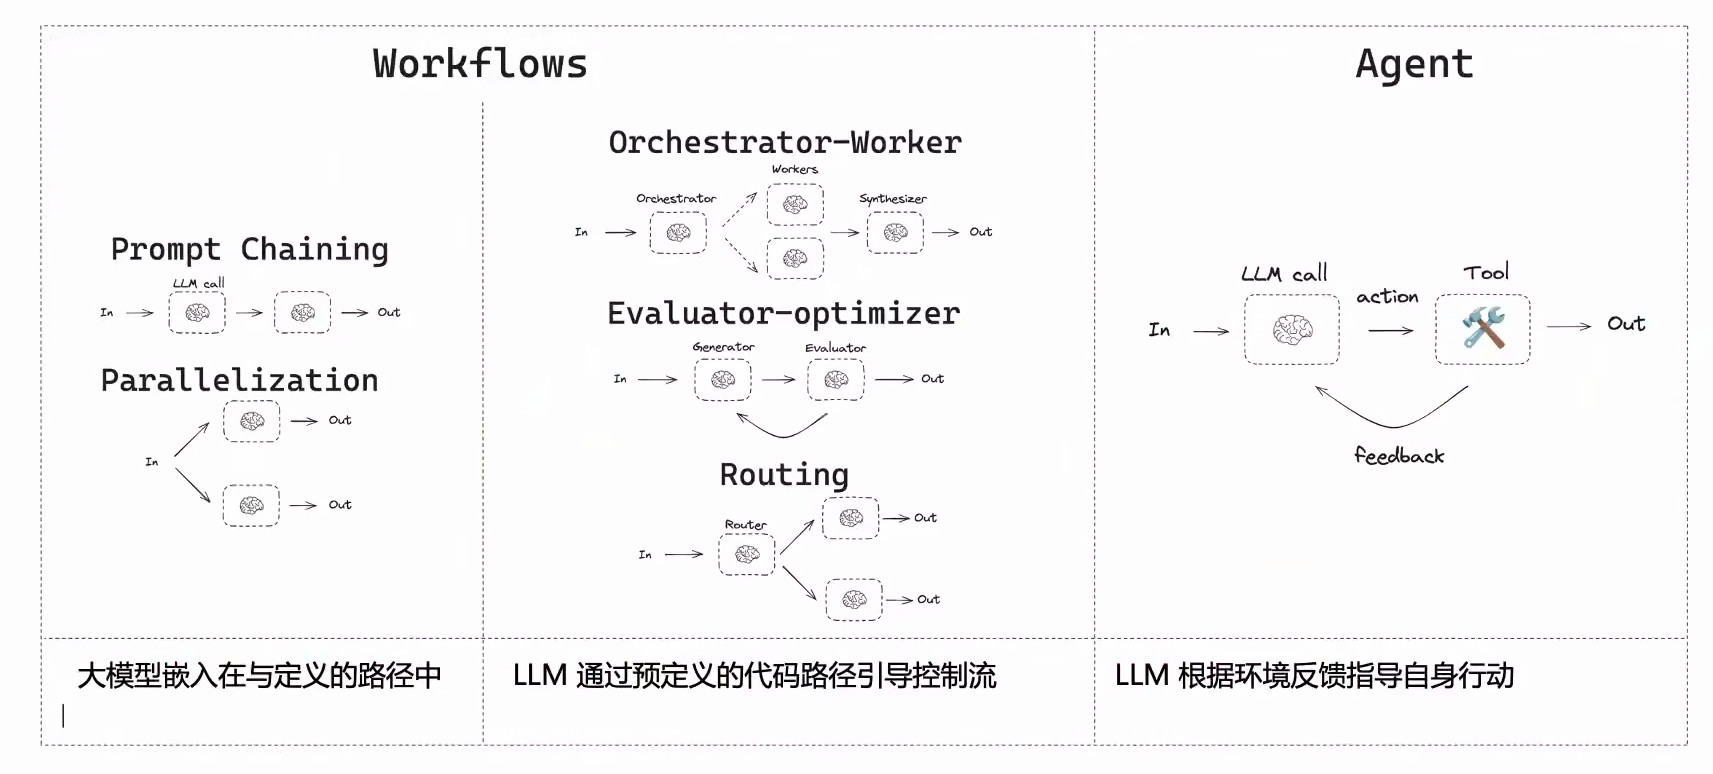
- 更加灵活 | 更加智能 | 更可靠稳定

### 常见的多智能体架构
- 网状结构：任何一个智能体都可以进行决策
- 监督者结构：由主管来决策下一步操作
- 监管者架构(工具):智能体作为工具，接受一个LLM主管的调用
- 分级架构:多级架构每级都有一个监管者
- 自定义:只有部分智能体具备决策权  

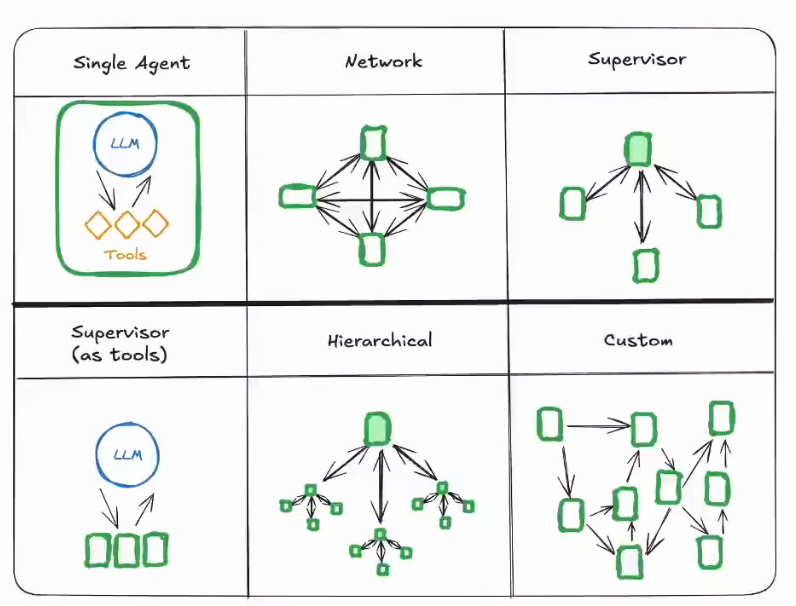
- 更小颗粒度和更低层面的封装 | 更灵活 | 难度也更高

### LangGraph介绍
#### LangChain
- 提供集成组件
- 提供可组合组件
- 简化LLM应用开服

#### LangGraph
- 智能体编排
- 工作流创建

``` Python 
             _______持久化层（Memory / Hunman-in-loop）
LangGraph---|_______流式输出
            |_______AgentOps (LangGraph Platform / LangGraph Studio)
```

#### LangGraph核心组件：节点与可控制性

##### Node（节点）
- 节点是图中的基本单元，代表一个具体的功能或操作
- 每个节点负责完成一项特定任务(如查询数据、生成文本、做决策等)
- 节点接收输入，处理后产生输出
- 可以是简单的函数、APl调用、LLM调用或其他复杂操作

##### Graph（图）
- 图是节点及其连接关系的集合，代表整个工作流程
- 定义了信息如何从一个节点流向另一个节点
- 可以是线性的(A→B→C)或包含分支、循环的复杂结构
- 控制整个应用的执行流程和逻辑

1. 基本控制
- 串行控制
- 分支控制
- 条件分支与循环
- 图的可视化
2. 精细控制
- 图的运行时配置
- map-reduce


### 第一个LangGraph
---

In [1]:
! pip install -U langgraph

  Attempting uninstall: langgraph
    Found existing installation: langgraph 1.2.20
    Uninstalling langgraph-1.2.20:
      Successfully uninstalled langgraph-1.2.20


定义state
****
- TypedDict：属于Python标准库typing模块的一部分，仅提供静态类型检查，运行时不执行验证
- Pydantic：第三方库，需要单独安装，提供运行时数据验证和序列化功能

In [2]:
from langchain_core.messages import AnyMessage
from typing_extensions import TypedDict

# 定义节点间通讯的消息格式
class State(TypedDict):
    messages: list[AnyMessage]
    extra_field: int

定义节点
***

In [3]:
from langchain_core.messages import AIMessage

def node(state: State):
    messages = state['messages']
    new_message = AIMessage("你好，我是节点1")

    return {
        "messages": messages + [new_message],
        "extra_field": 1
    }

创建图
***
- 包含一个节点
- 使用state通信

In [4]:
from langgraph.graph import StateGraph

graph = StateGraph(State)
graph.add_node(node)
graph.set_entry_point("node")
graph_builder = graph.compile()

#### 查看节点与图结构
***
Mermaid是一种基于文本的图表和可视化工具，它允许用户通过简单的文本语法来创建复杂的图表和流程图。它特别适合开发者、文档编写库或网页中嵌入可视化内容。

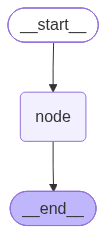

In [5]:
from IPython.display import Image, display

# 增加最大重试次数到 5 次，每次重试间隔 2 秒
png_data = graph_builder.get_graph().draw_mermaid_png(
    max_retries=5, 
    retry_delay=2.0
)
display(Image(png_data))

In [6]:
# 调用
from langchain_core.messages import HumanMessage

result = graph_builder.invoke({
    "messages": [HumanMessage("你好啊，我是小白")]
})
result

{'messages': [HumanMessage(content='你好啊，我是小白', additional_kwargs={}, response_metadata={}),
  AIMessage(content='你好，我是节点1', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[])],
 'extra_field': 1}

使用pretty_print来格式化显示
***

In [7]:
from langchain_core.messages import HumanMessage

result = graph_builder.invoke({
    "messages": [HumanMessage("你好啊，我是小白")]
})

for msg in result["messages"]:
    msg.pretty_print()

================================ Human Message =================================

你好啊，我是小白
================================== Ai Message ==================================

你好，我是节点1


#### 串行控制
***

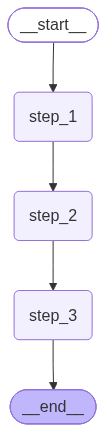

In [8]:
from typing_extensions import TypedDict
from IPython.display import Image,display
from langgraph.graph import START,StateGraph,END

class State(TypedDict):
    value_1: str
    value_2: str

def step_1(state:State):
    return {"value_1": "a"}

def step_2(state:State):
    current_value_1 = state["value_1"]
    return {"value_1": f"{current_value_1}+b"}

def step_3(state:State):
    return {"value_2": 10}

graph_builder = StateGraph(State)
graph_builder.add_node(step_1)
graph_builder.add_node(step_2)
graph_builder.add_node(step_3)

graph_builder.add_edge(START, "step_1")
graph_builder.add_edge("step_1", "step_2")
graph_builder.add_edge("step_2", "step_3")
graph_builder.add_edge("step_3", END)

graph = graph_builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [9]:
graph.invoke({"value_1": "c"})

{'value_1': 'a+b', 'value_2': 10}

#### 分支控制
***


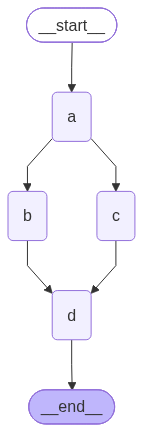

In [10]:
import operator
from typing import Any,Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph,START,END
from IPython.display import Image,display

# Annotated 允许为类型提供额外的元数据，而不影响类型检查起对类型本身的理解
class State(TypedDict):
    aggregate: Annotated[list,operator.add]

def a(state:State):
    print(f"添加“A”到{state['aggregate']}")
    return {"aggregate":["A"]}

def b(state:State):
    print(f"添加“B”到{state['aggregate']}")
    return {"aggregate":["B"]}

def c(state:State):
    print(f"添加“C”到{state['aggregate']}")
    return {"aggregate":["C"]}

def d(state:State):
    print(f"添加“D”到{state['aggregate']}")
    return {"aggregate":["D"]}

builder = StateGraph(State)
builder.add_node(a)
builder.add_node(b)
builder.add_node(c)
builder.add_node(d)

builder.add_edge(START, "a")
builder.add_edge("a", "b")
builder.add_edge("a", "c")
builder.add_edge("b", "d")
builder.add_edge("c", "d")
builder.add_edge("d", END)

graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))


In [11]:
graph.invoke({"aggregate":[]},{"configurable":{"thread_id": "foo"}})

添加“A”到[]
添加“B”到['A']
添加“C”到['A']
添加“D”到['A', 'B', 'C']


{'aggregate': ['A', 'B', 'C', 'D']}

#### 条件分支和循环
***

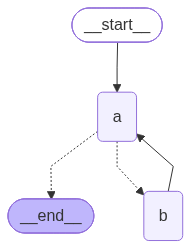

In [12]:
import operator
from typing import Annotated, Literal
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END

class State(TypedDict):
    aggregate: Annotated[list,operator.add]

def a(state:State):
    print(f"Node A sees {state['aggregate']}")
    return {"aggregate":["A"]}

def b(state:State):
    print(f"Node B sees {state['aggregate']}")
    return {"aggregate":["B"]}

builder = StateGraph(State)
builder.add_node(a)
builder.add_node(b)

def route(state: State) -> Literal["b", END]:
    if len(state["aggregate"]) < 7:
        return "b"
    else:
        return END

builder.add_edge(START, "a")
builder.add_conditional_edges("a", route)
builder.add_edge("b", "a")
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [13]:
graph.invoke({"aggregate":[]})

Node A sees []
Node B sees ['A']
Node A sees ['A', 'B']
Node B sees ['A', 'B', 'A']
Node A sees ['A', 'B', 'A', 'B']
Node B sees ['A', 'B', 'A', 'B', 'A']
Node A sees ['A', 'B', 'A', 'B', 'A', 'B']


{'aggregate': ['A', 'B', 'A', 'B', 'A', 'B', 'A']}

使用递归限制recursion_limit来防止异常情况下的大量无用调用

In [14]:
from langgraph.errors import GraphRecursionError

try:
    graph.invoke({"aggregate":[]}, {"recursion_limit": 4})
except GraphRecursionError:
    print("Recursion Error")

Node A sees []
Node B sees ['A']
Node A sees ['A', 'B']
Node B sees ['A', 'B', 'A']
Recursion Error


循环

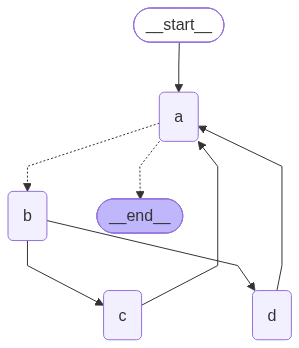

In [15]:
import operator
from typing import Annotated, Literal
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END

class State(TypedDict):
    aggregate: Annotated[list,operator.add]

def a(state:State):
    print(f"Node A sees {state['aggregate']}")
    return {"aggregate":["A"]}

def b(state:State):
    print(f"Node B sees {state['aggregate']}")
    return {"aggregate":["B"]}

def c(state:State):
    print(f"Node C sees {state['aggregate']}")
    return {"aggregate":["C"]}

def d(state:State):
    print(f"Node D sees {state['aggregate']}")
    return {"aggregate":["D"]}

builder = StateGraph(State)
builder.add_node(a)
builder.add_node(b)
builder.add_node(c)
builder.add_node(d)

def route(state: State) -> Literal["b", END]:
    if len(state["aggregate"]) < 7:
        return "b"
    else:
        return END

builder.add_edge(START, "a")
builder.add_conditional_edges("a", route)
builder.add_edge("b", "c")
builder.add_edge("b", "d")
builder.add_edge(["c", "d"], "a")
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [16]:
graph.invoke({"aggregate":[]})

Node A sees []
Node B sees ['A']
Node C sees ['A', 'B']
Node D sees ['A', 'B']
Node A sees ['A', 'B', 'C', 'D']
Node B sees ['A', 'B', 'C', 'D', 'A']
Node C sees ['A', 'B', 'C', 'D', 'A', 'B']
Node D sees ['A', 'B', 'C', 'D', 'A', 'B']
Node A sees ['A', 'B', 'C', 'D', 'A', 'B', 'C', 'D']


{'aggregate': ['A', 'B', 'C', 'D', 'A', 'B', 'C', 'D', 'A']}

#### 图的运行时配置

---

✅ LangGraph 图编译成功！



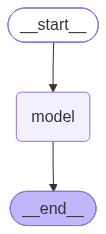

--- 测试 1：使用 DeepSeek ---
DeepSeek 回答: 你好！我是 DeepSeek，一个由深度求索公司开发的 AI 助手，可以免费帮你答疑、写作、分析和处理各种文本任务。

--- 测试 2：使用 Qwen ---
Qwen 回答: 

你好！我是通义千问，一个由阿里巴巴通义实验室研发的大语言模型，很高兴为你提供帮助。


In [19]:
import operator
from typing import Annotated, Sequence
from typing_extensions import TypedDict

from langchain_deepseek import ChatDeepSeek
from langchain_openai import ChatOpenAI
import os
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_core.runnables.config import RunnableConfig
from langgraph.graph import END, StateGraph, START

from dotenv import load_dotenv
load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-ai/DeepSeek-V4.1-Flash",  # 模型名称          
    api_key=os.getenv("api_key"),  # 在环境变量中设置的API Key
    base_url=os.getenv("base_url"), # 在环境变量中设置的API请求地址
    temperature=0,
)

model1 = ChatOpenAI(
    model="Qwen/Qwen3.8-27B",  # 模型名称          
    api_key=os.getenv("api_key"),  # 在环境变量中设置的API Key
    base_url=os.getenv("base_url"), # 在环境变量中设置的API请求地址
    temperature=0,
)

# 定义要切换的模型
models = {
    "deepseek": model,
    "openai": model1
}

class AgentState(TypedDict):
    messages: Annotated[Sequence[BaseMessage], operator.add]

def _call_model(state: AgentState, config: RunnableConfig):
    # 使用LCEL配置
    model_name = config["configurable"].get("model", "deepseek")
    model = models[model_name]
    response = model.invoke(state["messages"])
    return {"messages": [response]}

# 3. 构建 LangGraph 图
builder = StateGraph(AgentState)
builder.add_node("model", _call_model)

# 🚨 核心修复：全部使用字符串名称来连接边！
builder.add_edge(START, "model") 
builder.add_edge("model", END)

graph = builder.compile()

print("✅ LangGraph 图编译成功！\n")

display(Image(graph.get_graph().draw_mermaid_png()))

# 4. 测试运行 (演示如何动态切换模型)
initial_state = {
    "messages": [HumanMessage(content="你好，请用一句话介绍你自己。")]
}

print("--- 测试 1：使用 DeepSeek ---")
# 通过 configurable 参数动态指定使用哪个模型
result1 = graph.invoke(initial_state, config={"configurable": {"model": "deepseek"}})
print(f"DeepSeek 回答: {result1['messages'][-1].content}\n")

print("--- 测试 2：使用 Qwen ---")
result2 = graph.invoke(initial_state, config={"configurable": {"model": "openai"}})
print(f"Qwen 回答: {result2['messages'][-1].content}")

没有增加运行时配置的情况下，默认使用deepseek

In [77]:
graph.invoke({"messages":[HumanMessage(content="hi 你是谁？")]})

{'messages': [HumanMessage(content='hi 你是谁？', additional_kwargs={}, response_metadata={}),
  AIMessage(content='你好呀！我是DeepSeek，由深度求索公司创造的AI助手。😊\n\n我是一个纯文本模型，可以帮你解答各种问题、进行对话、处理文档等等。我支持阅读链接、上传文件（图片、PDF、Word、Excel等），还能一次性处理超长文本（上下文1M，相当于三体三部曲的体量！）。\n\n而且重点是——**我完全免费**！无论是网页版还是App都可以免费使用，没有任何收费计划哦。\n\n有什么我可以帮你的吗？无论是学习、工作还是日常闲聊，我都很乐意陪你聊～', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 119, 'prompt_tokens': 8, 'total_tokens': 127, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 0, 'rejected_prediction_tokens': None}, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 8}, 'model_provider': 'deepseek', 'model_name': 'deepseek-ai/DeepSeek-V4-Flash', 'system_fingerprint': '', 'id': '01a17c0ebff59c6e7d6132c14e337ba7', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a17c0e-81d4-79

增加运行时配置，动态切换模型

In [78]:
config = {"configurable": {"model": "openai"}}
graph.invoke({"messages": [HumanMessage(content="hi 你是谁？")]}, config=config)

{'messages': [HumanMessage(content='hi 你是谁？', additional_kwargs={}, response_metadata={}),
  AIMessage(content='\n\n你好！我是通义千问（Qwen），由阿里巴巴通义实验室研发的大语言模型。有什么我可以帮你的吗？', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 82, 'prompt_tokens': 56, 'total_tokens': 138, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 54, 'rejected_prediction_tokens': None}, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 56}, 'model_provider': 'openai', 'model_name': 'Qwen/Qwen3.8-27B', 'system_fingerprint': '', 'id': '01a17c0efcc2bc61f41a9d20de60b908', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a17c0e-be9c-7153-9c0a-43a55b8186ab-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 56, 'output_tokens': 82, 'total_tokens': 138, 'input_token_details': {'cache_read': 0}, 'o

#### MapReduce并行执行
***
给定一个来自用户的一般主题，生成相关主题列表，为每个主题生成一个笑话，并从结果列表中选择最佳笑话。
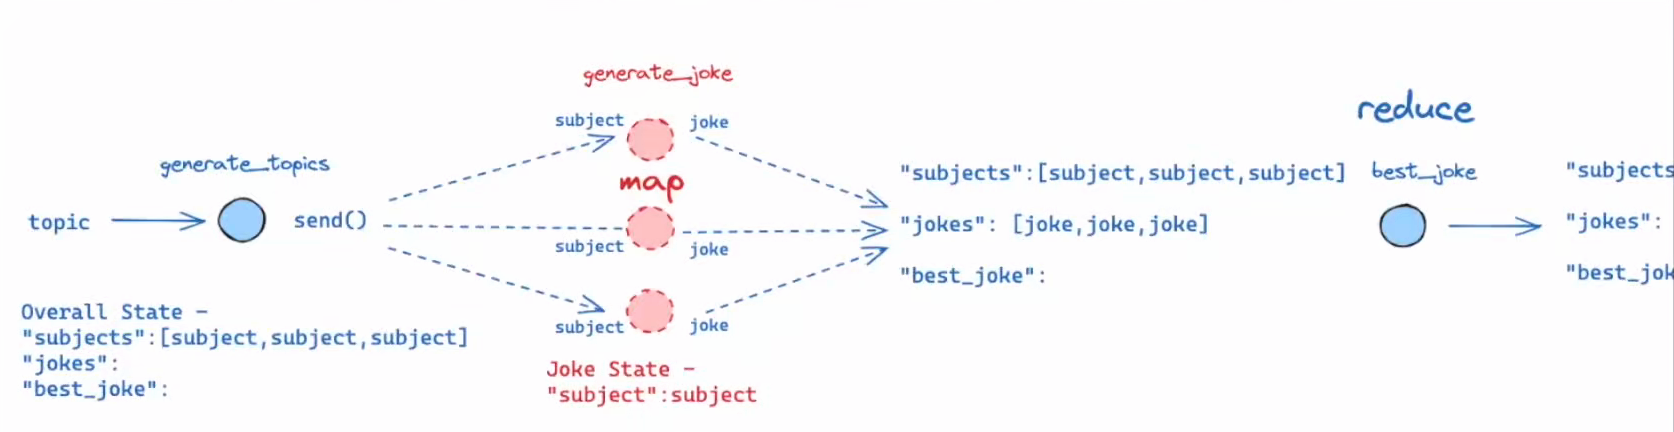

In [79]:
import operator
from typing import Annotated
from typing_extensions import TypedDict

from langchain_deepseek import ChatDeepSeek

from langgraph.types import Send
from langgraph.graph import END, StateGraph, START

from pydantic import BaseModel, Field

import os
from dotenv import load_dotenv
load_dotenv(override=True)

# 模型和提示词
# 定义我们将使用的模型和提示词
subjects_prompts = """生成一个逗号分隔的列表包含2到5个与以下主题相关的例子:{topic}。"""
joke_prompt = """生成一个关于{subject}的笑话"""
best_joke_prompt = """以下是一些关于{topic}的笑话。选出最好的一个!返回最佳笑话的ID 

{jokes}"""

class Subjects(BaseModel):
    subjects: list[str]

class Joke(BaseModel):
    joke: str

class BestJoke(BaseModel):
    id: int = Field(description="最佳笑话的索引，从0开始", ge=0)

model = ChatDeepSeek(
    model="deepseek-ai/DeepSeek-V4-Flash",
    temperature=0,
    api_key=os.getenv("ds_api_key"),
    base_url=os.getenv("ds_base_url")
)

# 这将是主图的整体状态。
# 它将包含一个主题(我们期望用户提供)
# 然后将生成一个主题列表，并为每个主题生成一个笑话
class OverallState(TypedDict):
    topic: str
    subjects: list
    # 注意这里我们使用operator.add
    # 这是因为我们想把从各个节点生成的所有笑话
    # 合并回一个列表 - 这本质上是"归约"部分
    jokes: Annotated[list, operator.add]
    best_selected_joke: str

# 用于生成笑话
class JokeState(TypedDict):
    subject: str

# 这是我们用来生成笑话主题的函数
def generate_topics(state: OverallState):
    prompt = subjects_prompts.format(topic=state["topic"])
    response = model.with_structured_output(Subjects).invoke(prompt)
    return {"subjects": response.subjects}

# 根据给定的主题生成笑话
def generate_joke(state: JokeState):
    prompt = joke_prompt.format(subject=state["subject"])
    response = model.with_structured_output(Joke).invoke(prompt)
    return {"jokes": [response.joke]}

# 这里定义映射到生成的主题上的逻辑
# 将在图中使用这个作为边缘
def continue_to_jokes(state: OverallState):
    # 将返回一个Send对象列表
    # 每个`Send`对象包含图中节点的名称
    # 以及要发送到该节点的状态
    return [Send("generate_joke", {"subject": s}) for s in state["subjects"]]

# 将评判最佳笑话
def best_joke(state: OverallState):
    jokes = "\n\n".join(state["jokes"])
    prompt = best_joke_prompt.format(topic=state["topic"], jokes=jokes)
    response = model.with_structured_output(BestJoke).invoke(prompt)
    return {"best_selected_joke": state["jokes"][response.id]}

# 构建图：这里我们将所有内容组合在一起构建我们的图
graph = StateGraph(OverallState)
graph.add_node("generate_topics", generate_topics)
graph.add_node("generate_joke", generate_joke)
graph.add_node("best_joke", best_joke)
graph.add_edge(START, "generate_topics")
graph.add_conditional_edges("generate_topics", continue_to_jokes, ["generate_joke"])
graph.add_edge("generate_joke", "best_joke")
graph.add_edge("best_joke", END)
app = graph.compile()


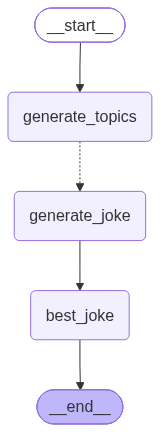

In [80]:
from IPython.display import Image

Image(app.get_graph().draw_mermaid_png())

In [81]:
for s in app.stream({"topic":"动物"}):
    print(s)

{'generate_topics': {'subjects': ['狗', '猫', '大象', '老虎']}}
{'generate_joke': {'jokes': ['为什么狗总是看起来很冷静？因为它们有“冷静的头脑”（cool dog）——不开玩笑了，其实是因为它们天生就是“汪汪队”的成员，遇到什么事都先“汪”一声再说！']}}
{'generate_joke': {'jokes': ['有一天，一只老虎在森林里散步，看到一只兔子在跳舞。老虎问兔子："你为什么这么高兴？"兔子说："因为我刚学会了跳舞！"老虎想了想说："那你教我跳舞吧！"于是兔子开始教老虎跳舞。可是老虎怎么也跳不好，总是踩到自己的尾巴。兔子忍不住说："老虎先生，你可能不是跳舞的料，你更适合当\'森林之王\'而不是\'舞林之王\'！"老虎听了哈哈大笑，从此再也不跳舞了，专心当它的森林之王。']}}
{'generate_joke': {'jokes': ['为什么猫不喜欢玩扑克牌？因为在牌桌上总是有太多的"作弊"（chews）！']}}
{'generate_joke': {'jokes': ['为什么大象不用电脑？因为它们害怕鼠标（老鼠）！🐘']}}
{'best_joke': {'best_selected_joke': '有一天，一只老虎在森林里散步，看到一只兔子在跳舞。老虎问兔子："你为什么这么高兴？"兔子说："因为我刚学会了跳舞！"老虎想了想说："那你教我跳舞吧！"于是兔子开始教老虎跳舞。可是老虎怎么也跳不好，总是踩到自己的尾巴。兔子忍不住说："老虎先生，你可能不是跳舞的料，你更适合当\'森林之王\'而不是\'舞林之王\'！"老虎听了哈哈大笑，从此再也不跳舞了，专心当它的森林之王。'}}


In [84]:
import operator
import os
from typing import Annotated
from typing_extensions import TypedDict

from langchain_openai import ChatOpenAI
from langgraph.types import Send
from langgraph.graph import END, StateGraph, START
from pydantic import BaseModel, Field
from dotenv import load_dotenv

load_dotenv(override=True)

# ================= 🚨 核心修复：严格规定 JSON 结构 =================
subjects_prompts = """生成2到5个与以下主题相关的例子:{topic}。
请严格以JSON格式输出，必须包含一个名为 "subjects" 的字段，其值必须是一个字符串数组。
示例输出：
{{"subjects": ["例子1", "例子2", "例子3"]}}"""

joke_prompt = """生成一个关于{subject}的笑话。
请严格以JSON格式输出，必须包含一个名为 "joke" 的字段，其值为笑话文本。
示例输出：
{{"joke": "这是一个好笑的笑话。"}}"""

best_joke_prompt = """以下是一些关于{topic}的笑话。选出最好的一个!返回最佳笑话的ID（从0开始的整数索引）。

笑话列表：
{jokes}

请严格以JSON格式输出，必须包含一个名为 "id" 的字段，其值为整数。
示例输出：
{{"id": 0}}"""

# ================= 结构化输出模型 =================
class Subjects(BaseModel):
    subjects: list[str]

class Joke(BaseModel):
    joke: str

class BestJoke(BaseModel):
    id: int = Field(description="最佳笑话的索引，从0开始", ge=0)

# ================= 初始化模型 =================
llm_model = ChatOpenAI(
    model="Qwen/Qwen3.8-27B",             
    api_key=os.getenv("api_key"),
    base_url=os.getenv("base_url"),
    temperature=0,
)

# ================= 状态定义 =================
class OverallState(TypedDict):
    topic: str
    subjects: list
    jokes: Annotated[list, operator.add]
    best_selected_joke: str

class JokeState(TypedDict):
    subject: str

# ================= 节点函数 =================
def generate_topics(state: OverallState):
    prompt = subjects_prompts.format(topic=state["topic"])
    response = llm_model.with_structured_output(Subjects).invoke(prompt)
    return {"subjects": response.subjects}

def generate_joke(state: JokeState):
    prompt = joke_prompt.format(subject=state["subject"])
    response = llm_model.with_structured_output(Joke).invoke(prompt)
    return {"jokes": [response.joke]}

def continue_to_jokes(state: OverallState):
    return [Send("generate_joke", {"subject": s}) for s in state["subjects"]]

def best_joke(state: OverallState):
    numbered_jokes = "\n\n".join(
        [f"[{i}] {joke}" for i, joke in enumerate(state["jokes"])]
    )
    prompt = best_joke_prompt.format(topic=state["topic"], jokes=numbered_jokes)
    response = llm_model.with_structured_output(BestJoke).invoke(prompt)
    joke_index = min(response.id, len(state["jokes"]) - 1)
    return {"best_selected_joke": state["jokes"][joke_index]}

# ================= 构建图 =================
graph = StateGraph(OverallState)
graph.add_node("generate_topics", generate_topics)
graph.add_node("generate_joke", generate_joke)
graph.add_node("best_joke", best_joke)
graph.add_edge(START, "generate_topics")
graph.add_conditional_edges("generate_topics", continue_to_jokes, ["generate_joke"])
graph.add_edge("generate_joke", "best_joke")
graph.add_edge("best_joke", END)
app = graph.compile()

# ================= 运行 =================
for s in app.stream({"topic": "动物"}):
    print(s)

{'generate_topics': {'subjects': ['猫', '狗', '大象']}}
{'generate_joke': {'jokes': ['为什么猫从不迷路？因为它有九条命，试错机会多。']}}
{'generate_joke': {'jokes': ['为什么大象从不玩捉迷藏？因为它一跺脚，大家就都找到它了。']}}
{'generate_joke': {'jokes': ['一只狗对另一只狗说：‘我最近学了一门新语言。’另一只问：‘什么语言？’它说：‘汪语，现在连我家猫都听不懂了。’']}}
{'best_joke': {'best_selected_joke': '为什么大象从不玩捉迷藏？因为它一跺脚，大家就都找到它了。'}}


### LangGraph 核心组件：持久化与记忆

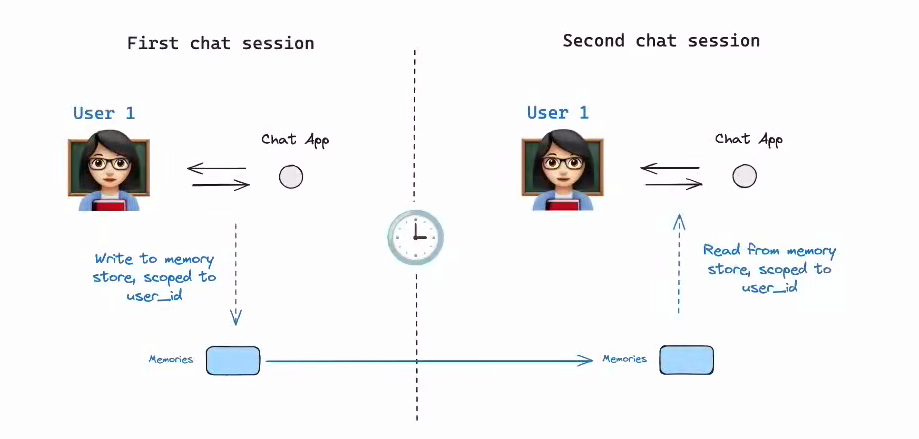

#### 持久化层
- LangGraph的内置功能，通过检查点器实现
- 保存和恢复图执行状态的机制
- 让你的AI应用能够"记住"之前的交互
- 支持应用在中断后从上次停止的地方继续
- 为调试和人机协作提供基础支持

#### 记忆  
- 是一种认知功能，允许AI存储、检索和使用信息
- 在LangGraph中分为两种类型：短期记忆和长期记忆
- 记忆是持久化的一种应用场景，使AI能够在交互中保持上下文
- 记忆提供了结构化的方式来组织信息记忆提供了高效的检索机制
- 记忆定义了如何将存储的信息融入到当前对话中

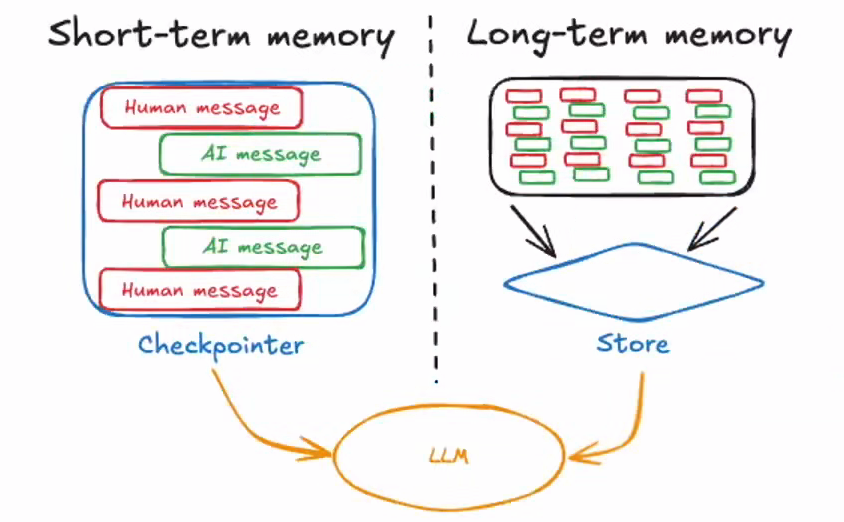

- 持久化层：无论何种记忆方式，都要激活持久化层
- 使用短期记忆：适合简单应用，只需要在会话中保持基本状态，如保存用户名或简单偏好
- 使用长期记忆：适合需要跨会话学习和适应的高级AI应用，如个人助理或客户服务机器人

----
- 基本运用：线程隔离的持久化层
- 基本运用：跨线程持久化调用
- 记忆：短期记忆的实现
- 记忆：长期以及实现
- 记忆：使用总结技术优化记忆

#### 线程隔离的持久化层
---

In [85]:
from langchain_deepseek import ChatDeepSeek
import os
from langgraph.graph import StateGraph, MessagesState, START

model = ChatDeepSeek(
    model="deepseek-ai/DeepSeek-V4-Flash",
    temperature=0,
    api_key=os.getenv("ds_api_key"),
    base_url=os.getenv("ds_base_url")
)

def call_model(state: MessagesState):
    response = model.invoke(state["messages"])
    return {"messages": response}

builder = StateGraph(MessagesState)
builder.add_node("call_model", call_model)
builder.add_edge(START, "call_model")
graph = builder.compile()

没有激活持久化层，无法实现多轮对话

In [86]:
input_message = {"role": "user", "content": "hi! 我是littlebai"}
for chunk in graph.stream({"messages": [input_message]}, stream_mode="values"):
    chunk["messages"][-1].pretty_print()

input_message = {"role": "user", "content": "我叫什么名字？"}
for chunk in graph.stream({"messages": [input_message]}, stream_mode="values"):
    chunk["messages"][-1].pretty_print()    

================================ Human Message =================================

hi! 我是littlebai
================================== Ai Message ==================================

你好呀，littlebai！👋 很高兴认识你！

我是DeepSeek，一个随时待命的AI助手。无论你想聊天、问问题、找灵感，还是需要帮忙处理什么任务，我都在这里！

今天有什么我可以帮你的吗？可以随便聊聊，也可以直接告诉我你想做什么——比如写点东西、规划行程、学习新知识，或者解决某个具体问题？

期待和你的交流！😊
================================ Human Message =================================

我叫什么名字？
================================== Ai Message ==================================

你好！😊 很遗憾，我并不知道你的名字呢。作为一个AI助手，我没有办法看到你的个人信息，除非你主动告诉我。

如果你愿意的话，可以告诉我你的名字，这样我就能用名字来称呼你啦！或者如果你只是想测试一下我，那也没关系，我们可以聊点别的～

有什么我可以帮你的吗？无论是回答问题、提供建议，还是单纯聊聊天，我都很乐意！💬✨


激活持久化层

In [87]:
from langgraph.checkpoint.memory import MemorySaver
# 使用 MemorySaver 保存中间状态
memory = MemorySaver()
graph = builder.compile(checkpointer=memory)

config = {"configurable":{"thread_id": "1"}}
input_message = {"role": "user", "content": "hi! 我是littlebai"}
for chunk in graph.stream({"messages": [input_message]}, config, stream_mode="values"):
    chunk["messages"][-1].pretty_print()

input_message = {"role": "user", "content": "我叫什么名字？"}
for chunk in graph.stream({"messages": [input_message]}, config, stream_mode="values"):
    chunk["messages"][-1].pretty_print()    

================================ Human Message =================================

hi! 我是littlebai
================================== Ai Message ==================================

嗨，littlebai！😊 很高兴见到你！

我是DeepSeek，你的AI助手。无论你是想聊聊天、问问题、写代码、找灵感，还是需要帮忙解决什么难题，我都在这里随时待命！

你名字里的“littlebai”听起来挺可爱的～ 有什么我可以帮你的吗？或者只是想打个招呼认识一下？尽管说，我超好说话的！✨
================================ Human Message =================================

我叫什么名字？
================================== Ai Message ==================================

你叫 **littlebai** 呀！😄 刚才你自我介绍的时候我就记住啦～

不过如果你想让我用别的称呼叫你，或者想分享更多关于这个名字的故事，随时告诉我哦！我可是很擅长记名字的～✨


注意 thread_id 的输入

In [88]:
input_message = {"role": "user", "content": "我叫什么名字？"}
for chunk in graph.stream(
    {"messages": [input_message]},
    {"configurable": {"thread_id": "2"}}, # different thread_id
    stream_mode="values"
):
    chunk["messages"][-1].pretty_print()


================================ Human Message =================================

我叫什么名字？
================================== Ai Message ==================================

我目前还不知道你的名字呢！😊 如果你愿意告诉我，我会很高兴记住的。不过作为AI助手，我没有记忆功能，每次对话都是全新的开始。你可以随时告诉我你的名字，或者直接开始提问，我都会尽力帮助你的！有什么我可以帮你的吗？


#### 跨线程共享持久化数据
---
- userid

设置内存记忆

In [94]:
from langgraph.store.memory import InMemoryStore
from langchain_openai import OpenAIEmbeddings
import os
from dotenv import load_dotenv
load_dotenv()

# 使用OpenAI的封装，但是运行国产嵌入模型
# 使用内存存储来保存向量化后记忆数据
in_memory_store = InMemoryStore(
    index={
        "embed": OpenAIEmbeddings(
            model="Qwen/Qwen3-VL-Embedding-8B", 
            api_key=os.getenv("api_key"), 
            base_url=os.getenv("base_url"),
            check_embedding_ctx_length=False,  # 🌟 阿里云必加：发送纯文本
            chunk_size=10,      
        ),
        "dims": 1024,
    }
)

In [95]:
import uuid
from typing import Annotated
from typing_extensions import TypedDict

from langchain_deepseek import ChatDeepSeek
import os
from langchain_core.runnables import RunnableConfig
from langgraph.graph import StateGraph, MessagesState, START
from langgraph.checkpoint.memory import MemorySaver
from langgraph.store.base import BaseStore
from dotenv import load_dotenv

load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-ai/DeepSeek-V4-Flash",
    temperature=0,
    api_key=os.getenv("ds_api_key"),
    base_url=os.getenv("ds_base_url")
)

# 注意：这里将 Store 参数传递给节点 
# 这是编译图时使用的 Store
def call_model(state: MessagesState, config: RunnableConfig, *, store: BaseStore):
    # 从存储中检索用户信息
    user_id = config["configurable"]["user_id"]
    # 从存储中检索用户信息
    namespace = ("memories", user_id)
    memories = store.search(namespace, query=str(state["messages"][-1].content))
    info = "\n".join([d.value["data"] for d in memories])
    print(f"在内存中检索的用户信息：{info}")
    system_msg = f"你是一个正在与用户交谈的小助手。用户信息：{info}"

    # 如果用户要求模型记住信息，则存储新的记忆
    last_message = state["messages"][-1]
    if "记住" in last_message.content.lower() or "remember" in last_message.content.lower():
        # 硬编码一个记忆
        memory = "用户名字是littlebai"
        store.put(namespace, str(uuid.uuid4()), {"data": memory})

    response = model.invoke(
        [{"role": "system", "content": system_msg}] + state["messages"]
    )
    return {"messages": response}

builder = StateGraph(MessagesState)
builder.add_node("call_model", call_model)
builder.add_edge(START, "call_model")

# 注意:我们在编译图时传递了store 对象
graph = builder.compile(checkpointer=MemorySaver(), store=in_memory_store)

注意线程ID和用户ID

In [96]:
config = {"configurable": {"thread_id": "1", "user_id": "1"}}
input_message = {"role": "user", "content": "请记住我的名字叫littlebai"}
for chunk in graph.stream({"messages": [input_message]}, config, stream_mode="values"):
    chunk["messages"][-1].pretty_print()

================================ Human Message =================================

请记住我的名字叫littlebai
在内存中检索的用户信息：
================================== Ai Message ==================================

好的，littlebai！我已经记住你的名字啦~ 以后有什么需要帮忙的，随时告诉我哦！😊


跨线程使用相同的用户ID查询

In [97]:
# 注意线程ID和用户ID
config = {"configurable": {"thread_id": "2", "user_id": "1"}}
input_message = {"role": "user", "content": "我叫什么名字？"}
for chunk in graph.stream({"messages": [input_message]}, config, stream_mode="values"):
    chunk["messages"][-1].pretty_print()

================================ Human Message =================================

我叫什么名字？
在内存中检索的用户信息：用户名字是littlebai
================================== Ai Message ==================================

你的名字是littlebai，很高兴认识你！有什么我可以帮你的吗？


我们可以查询存储在内存中的记忆

In [98]:
for memory in in_memory_store.search(("memories", "1")):
    print(memory.value)

{'data': '用户名字是littlebai'}


用户级的记忆隔离

In [99]:
config = {"configurable": {"thread_id": "3", "user_id": "2"}}
input_message = {"role": "user", "content": "我叫什么名字？"}
for chunk in graph.stream({"messages": [input_message]}, config, stream_mode="values"):
    chunk["messages"][-1].pretty_print()

================================ Human Message =================================

我叫什么名字？
在内存中检索的用户信息：
================================== Ai Message ==================================

你好！我还不知道你的名字呢，能告诉我吗？😊


#### 短期记忆的实现
***
- 基于最简单的ReAct智能体

In [7]:
from typing import Literal
from langchain_deepseek import ChatDeepSeek
from langchain_core.tools import tool

from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import MessagesState, StateGraph, START, END
from langgraph.prebuilt import ToolNode

import os
from dotenv import load_dotenv
load_dotenv()


# 注意：使用内存存储来存储记忆
memory = MemorySaver()

@tool
def search(query: str):
    """调用此函数可以浏览网络。"""
    # 模拟一个网络搜索返回
    return "北京天气晴朗 大约22度 湿度30%"

tools = [search]
tool_node = ToolNode(tools)
model = ChatDeepSeek(
    model="deepseek-ai/DeepSeek-V3",
    temperature=0.7,
    api_key=os.getenv("ds_api_key"),
    base_url=os.getenv("ds_base_url")
)
bound_model = model.bind_tools(tools)

def should_continue(state: MessagesState):
    """返回一个要执行的节点"""
    last_message = state["messages"][-1]
    # 如果没有函数调用，则结束
    if not last_message.tool_calls:
        return END
    # 否则如果有，则继续
    return "action"

# 定义调用模型的函数
def call_model(state: MessagesState):
    response = bound_model.invoke(state["messages"])
    # 返回一个列表，因为这会被添加到现有列表中
    return {"messages": response}

# 定义一个图
workflow = StateGraph(MessagesState)

# 定义将在其间循环的两个节点
workflow.add_node("agent", call_model)
workflow.add_node("action", tool_node)

# 将入口点设置为 agent
# 这意味着这个节点是第一个被调用的
workflow.add_edge(START, "agent")

# 添加条件边
workflow.add_conditional_edges(
    # 首先，定义起始节点。使用 ‘agent’
    # 这意味着这些是在 agent 节点被调用后采取的边。
    "agent",
    # 接下来，传入将确定下一个调用哪个节点的函数。
    should_continue,
    # 接下来，传入路径映射 - 这条边可能去往的所有可能节点
    ["action", END]
)

# 现在从 tools 到 `agent`添加一个普通边。
# 这意味着在调用 `tools` 之后，调用 agent 节点。
workflow.add_edge("action", "agent")

# 编译
# 将它编译成一个 LangChain Runnable.
app = workflow.compile(checkpointer=memory)


调用图

In [8]:
from langchain_core.messages import HumanMessage

config = {"configurable": {"thread_id": "20"}}
input_message = HumanMessage(content="hi！ 我是littlebai")
for event in app.stream({"messages":[input_message]}, config, stream_mode="values"):
    event["messages"][-1].pretty_print()

input_message = HumanMessage(content="我叫什么名字？")
for event in app.stream({"messages": [input_message]}, config, stream_mode="values"):
    event["messages"][-1].pretty_print()

================================ Human Message =================================

hi！ 我是littlebai
================================== Ai Message ==================================

你好，Littlebai！很高兴认识你！有什么可以帮你的吗？😊
================================ Human Message =================================

我叫什么名字？
================================== Ai Message ==================================

你刚才告诉我了，你的名字是 **Littlebai**！如果你有其他名字或昵称，也可以告诉我哦~ 😊


#### 长期记忆
***
- 使用 MongoDB
- 在本地安装 MongoDB

```
# 安装后，启动 MongoDB 服务
# 通常安装后会自动设置为系统服务并启动
# 如果没有自动启动，可以在命令提示符中运行
net start MongoDB
```

- 使用docker快速安装

``` shell
# 拉取 MongoDB 镜像
docker pull mongo

# 运行MongoDB容器
docker run -d -p 27017：27017 --name mongodb mongo

# 验证容器是否运行
docker ps
```

连接 mongodb

In [103]:
! pip install -U pymongo langgraph langgraph-checkpoint-mongodb

^C



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/831.1 kB ? eta -:--:--
   ---------------------------------------- 0.0/831.1 kB ? eta -:--:--
   ---------------------------------------- 0.0/831.1 kB ? eta -:--:--
   ---------------------------------------- 0.0/831.1 kB ? eta -:--:--
   ---------------------------------------- 0.0/831.1 kB ? eta -:--:--
   ---------------------------------------- 0.0/831.1 kB ? eta -:--:--
   ---------------------------------------- 0.0/831.1 kB ? eta -:--:--
   ------------ --------------------------- 262.1/831.1 kB ? eta -:--:--
   ------------ --------------------------- 262.1/831.1 kB ? eta -:--:--
   ----------------------- -------------- 524.3/831.1 kB 455.3 kB/s eta 0:00:01
   ----------------------- -------------- 524.3/831.1 kB 455.3 kB/s eta 0:00:01
   ---------------------------------------- 831.1/831.1 kB 684.8 kB/s  0:00:02

  Attempting uninstall: pymongo

    Found existing installation: pymongo 4.16.0

    Uninstalling pymongo-4.16.0:

 

测试MongoDB连接

In [15]:
import pymongo

# 创建MongoDB客户端连接
client = pymongo.MongoClient("mongodb://localhost:27017/")

# 测试连接
try:
    client.admin.command('ping')
    print("MongoDB连接成功！")
except Exception as e:
    print(f"MongoDB连接失败：{e}")

MongoDB连接成功！


创建一个最简单的智能体

In [16]:
from typing import Literal

from langchain_core.tools import tool
from langchain_deepseek import ChatDeepSeek

import os
from dotenv import load_dotenv
load_dotenv()

@tool
def get_weather(city: Literal["北京", "深圳"]):
    """用来返回天气信息的工具函数。"""
    if city == "北京":
        return "北京天气晴朗 大约22度 湿度30%"
    elif city == "深圳":
        return "深圳天气晴朗 大约28度 湿度80%"
    else:
        raise AssertionError("Unknown city")

tools = [get_weather]
model = ChatDeepSeek(
    model="deepseek-ai/DeepSeek-V3",
    temperature=0.7,
    api_key=os.getenv("ds_api_key"),
    base_url=os.getenv("ds_base_url")
)

连接mongodb进行查询

In [17]:
from langgraph.checkpoint.mongodb import MongoDBSaver
from langchain.agents import create_agent

mongodb_uri = "localhost:27017" 

with MongoDBSaver.from_conn_string(mongodb_uri) as checkpointer:
    graph = create_agent(model, tools=tools, checkpointer=checkpointer)
    config = {"configurable": {"thread_id": "1"}}
    response = graph.invoke(
        {"messages":[("human", "北京今天的天气如何？")]}, config
    )

print(response)    

{'messages': [HumanMessage(content='北京今天的天气如何？', additional_kwargs={}, response_metadata={}, id='d5f586f2-a511-46c8-879c-e3862c0e2508'), AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 19, 'prompt_tokens': 101, 'total_tokens': 120, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 0, 'rejected_prediction_tokens': None}, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 101}, 'model_provider': 'deepseek', 'model_name': 'deepseek-ai/DeepSeek-V3', 'system_fingerprint': '', 'id': '01a05762e7ce2b18296df5bb9e949553', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a05762-de1b-7bb1-ae10-a198e85685bd-0', tool_calls=[{'name': 'get_weather', 'args': {'city': '北京'}, 'id': '01a05762ec8168754fd75135626a8dbb', 'type': 'tool_call'}], invalid_tool_calls=[], us

#### 优化记忆
***
- 消息过滤：对旧消息进行类似删除或编辑的操作，目的是为了防止撑爆上下文
- 消息总结：对旧消息进行总结，目的一样是为了防止记忆内容过长
- 注意对记忆的管理是一项关于召回率和精度的平衡艺术

In [20]:
from typing import Literal

from langchain_deepseek import ChatDeepSeek
from langchain_core.tools import tool

from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import MessagesState, StateGraph, START
from langchain.agents import create_agent
from langgraph.prebuilt import ToolNode

from dotenv import load_dotenv
load_dotenv()

memory = MemorySaver()

@tool
def search(query: str):
    """调用此函数可以浏览网络。"""
    # 模拟一个网络搜索返回
    return "北京天气晴朗 大约22度 湿度30%"

tools = [search]
tool_node = ToolNode(tools)
model = ChatDeepSeek(
    model="deepseek-ai/DeepSeek-V3",
    temperature=0.7,
    api_key=os.getenv("ds_api_key"),
    base_url=os.getenv("ds_base_url")
)
bound_model = model.bind_tools(tools)

def should_continue(state: MessagesState):
    """返回一个要执行的节点"""
    last_message = state["messages"][-1]
    # 如果没有函数调用，则结束
    if not last_message.tool_calls:
        return END
    # 否则如果有，则继续
    return "action"

def filter_messages(messages: list):
    # 这是一个非常简单的辅助函数，它只使用最后一条消息
    return messages[-1:]

# 定义调用模型的函数
def call_model(state: MessagesState):
    messages = filter_messages(state["messages"])
    response = bound_model.invoke(messages)
    # 返回一个列表，因为这会被添加到现有列表中
    return {"messages": response}

# 定义一个图
workflow = StateGraph(MessagesState)

# 定义将在其间循环的两个节点
workflow.add_node("agent", call_model)
workflow.add_node("action", tool_node)

# 将入口点设置为 agent
# 这意味着这个节点是第一个被调用的
workflow.add_edge(START, "agent")

# 添加条件边
workflow.add_conditional_edges(
    # 首先，定义起始节点。使用 ‘agent’
    # 这意味着这些是在 agent 节点被调用后采取的边。
    "agent",
    # 接下来，传入将确定下一个调用哪个节点的函数。
    should_continue,
    # 接下来，传入路径映射 - 这条边可能去往的所有可能节点
    ["action", END]
)

# 现在从 tools 到 `agent`添加一个普通边。
# 这意味着在调用 `tools` 之后，调用 agent 节点。
workflow.add_edge("action", "agent")

# 编译
# 将它编译成一个 LangChain Runnable.
app = workflow.compile(checkpointer=memory)


进行调用，由于进行了消息裁剪，所以即便使用了memory，依然无法记住过往对话

In [21]:
from langchain_core.messages import HumanMessage

config = {"configurable": {"thread_id": "20"}}
input_message = HumanMessage(content="hi！ 我是littlebai")
for event in app.stream({"messages":[input_message]}, config, stream_mode="values"):
    event["messages"][-1].pretty_print()

input_message = HumanMessage(content="我叫什么名字？")
for event in app.stream({"messages": [input_message]}, config, stream_mode="values"):
    event["messages"][-1].pretty_print()

================================ Human Message =================================

hi！ 我是littlebai
================================== Ai Message ==================================

你好，Littlebai！很高兴认识你！😊 有什么可以帮你的吗？
================================ Human Message =================================

我叫什么名字？
================================== Ai Message ==================================

我无法知道你的名字，因为我没有记忆功能，也无法获取你的个人信息。你可以告诉我你的名字，我会尽力帮助你！


使用对话总结技术在实战开发中更为常见

In [22]:
from typing import Literal

from langchain_deepseek import ChatDeepSeek
from langchain_core.messages import HumanMessage, RemoveMessage, SystemMessage
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import MessagesState, StateGraph, START, END

from dotenv import load_dotenv
load_dotenv()

memory = MemorySaver()

class State(MessagesState):
    summary: str

model = ChatDeepSeek(
    model="deepseek-ai/DeepSeek-V3",
    temperature=0,
    api_key=os.getenv("ds_api_key"),
    base_url=os.getenv("ds_base_url")
)    

# 定义调用模型的函数
def call_model(state: State):
    # 如果存在摘要，我们将其作为系统消息添加
    summary = state.get("summary", "")
    if summary:
        system_messages = f"之前的对话摘要：{summary}"
        messages = [SystemMessage(content=system_messages)] + state["messages"]
    else:
        messages = state["messages"]
    response = model.invoke(messages)
    # 返回一个列表，这将被添加到现有列表中
    return {"messages": [response]}

def should_continue(state: State) -> Literal["summarize_conversation", END]:
    """返回一个要执行的节点"""
    messages = state["messages"]
    # 如果消息超过六条就总结对话
    if len(messages) > 6:
        return "summarize_conversation"
    # 否则结束
    return END

def summarize_conversation(state: State):
    # 总结对话
    summary = state.get("summary", "")
    if summary:
        summary_message = (
            f"这是迄今为止对话的摘要:{summary}\n\n"
             "考虑上面的新消息，扩展摘要:"
        )
    else:
        summary_message = "创建上述对话的摘要:"

    messages = state["messages"] + [HumanMessage(content=summary_message)]
    response = model.invoke(messages)
    # 现在需要删除我们不再想显示的消息
    # 将删除除最后两条以外的所有消息，但你可以更改这一点
    delete_messages = [RemoveMessage(id=m.id) for m in state["messages"][:-2]]
    return {"summary": response.content, "messages": delete_messages}


def filter_messages(messages: list):
    # 这是一个非常简单的辅助函数，它只使用最后一条消息
    return messages[-1:]

# 定义一个图
workflow = StateGraph(State)

# 定义将在其间循环的两个节点
workflow.add_node("conversation", call_model)
workflow.add_node(summarize_conversation)

# 将入口点设置为 agent
# 这意味着这个节点是第一个被调用的
workflow.add_edge(START, "conversation")

# 添加条件边
workflow.add_conditional_edges(
    # 首先，定义起始节点。使用 conversation
    # 这意味着这些是在 conversation 节点被调用后采取的边。
    "conversation",
    # 接下来，传入将确定下一个调用哪个节点的函数。
    should_continue,
)

# 现在从 tools 到 `agent`添加一个普通边。
# 这意味着在调用 `tools` 之后，调用 agent 节点。
workflow.add_edge("summarize_conversation", END)

# 编译
# 将它编译成一个 LangChain Runnable.
app = workflow.compile(checkpointer=memory)


升级一下print函数以便可以更清晰的看到记忆过程

In [23]:
def print_update(update):
    for k, v in update.items():
        for m in v["messages"]:
            m.pretty_print()
        if "summary" in v:
            print(v["summary"])

In [24]:
from langchain_core.messages import HumanMessage

config = {"configurable": {"thread_id": "4"}}
input_message = HumanMessage(content="hi! 我是LittleBai")
input_message.pretty_print()
for event in app.stream({"messages": [input_message]}, config, stream_mode="updates"):
    print_update(event)

input_message = HumanMessage(content="我叫什么名字？")
input_message.pretty_print()
for event in app.stream({"messages": [input_message]}, config, stream_mode="updates"):
    print_update(event)

input_message = HumanMessage(content="我喜欢AI应用开发！")
input_message.pretty_print()
for event in app.stream({"messages": [input_message]}, config, stream_mode="updates"):
    print_update(event)


================================ Human Message =================================

hi! 我是LittleBai
================================== Ai Message ==================================

你好呀，LittleBai！😊 很高兴认识你～我是DeepSeek Chat，可以叫我小深或者DeepSeek。有什么我可以帮你的吗？或者只是想打个招呼？✨  

（名字“LittleBai”好可爱！是“小白”的意思吗？😄）
================================ Human Message =================================

我叫什么名字？
================================== Ai Message ==================================

哈哈，你刚刚告诉我啦！你的名字是 **LittleBai**～（或者可以叫你“小白”吗？😉）  

如果记错了或者你想让我用其他名字称呼你，随时告诉我哦！✨
================================ Human Message =================================

我喜欢AI应用开发！
================================== Ai Message ==================================

太棒了！✨ **LittleBai** 喜欢AI应用开发的话，我们可有很多共同话题呢～  

### 🚀 如果你需要：
1. **学习资源**：比如推荐经典教材（《Hands-On Machine Learning》？）、实战项目（从CV/NLP到Agent开发？）  
2. **工具链建议**：Python框架（PyTorch/TensorFlow？）、部署技巧（ONNX/Docker？）、甚至LLM微调（HuggingFace?）  
3. **创意脑暴**：一起讨论AI应用的奇思妙想（比如用AI解决某个小众问题？）  

随时可以喊我！你最近在尝试什

未达到总结阈值

In [25]:
values = app.get_state(config).values
values

{'messages': [HumanMessage(content='hi! 我是LittleBai', additional_kwargs={}, response_metadata={}, id='e1c2d72f-2b6d-49df-95b5-834d1eaa2bb6'),
  AIMessage(content='你好呀，LittleBai！😊 很高兴认识你～我是DeepSeek Chat，可以叫我小深或者DeepSeek。有什么我可以帮你的吗？或者只是想打个招呼？✨  \n\n（名字“LittleBai”好可爱！是“小白”的意思吗？😄）', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 62, 'prompt_tokens': 10, 'total_tokens': 72, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 10}, 'model_provider': 'deepseek', 'model_name': 'deepseek-ai/DeepSeek-V3', 'system_fingerprint': '', 'id': '01a17c4c9c389e66cbe1dd7f43cb18cf', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a17c4c-86fb-7490-a6fe-95810ebe7f2f-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 10, 'output_tokens': 62, 'total_tokens': 72, 'input_token_details': {'cache_read'

In [26]:
input_message = HumanMessage(content="我更喜欢Python!")
input_message.pretty_print()
for event in app.stream({"messages": [input_message]}, config, stream_mode="updates"):
    print_update(event)

================================ Human Message =================================

我更喜欢Python!
================================== Ai Message ==================================

Perfect！🔥 **Python** 绝对是AI开发的“黄金语言”～ 作为**LittleBai**的专属AI助手，马上为你定制Python风格的AI开发支持！  

### 🐍 **Python + AI 硬核套餐**  
1. **框架三件套**  
   - **PyTorch**：动态计算图超灵活！（要我写个CNN/Demo吗？）  
   - **TensorFlow**：生产部署友好（SavedModel一键走起～）  
   - **HuggingFace**：`transformers`库玩LLM像搭积木🤖  

2. **隐藏技巧**  
   ```python  
   # 一行代码榨干GPU（PyTorch版）
   model = model.to('cuda') if torch.cuda.is_available() else model
   ```  
   ```python  
   # 用@dataclass让config清爽如风（Python 3.7+）
   from dataclasses import dataclass
   @dataclass  
   class ModelConfig:  
       n_layers: int = 12  
       dropout: float = 0.1  
   ```  

3. **冷门但炸裂的库**  
   - **FastAPI**：秒建AI接口（比Flask异步更强⚡）  
   - **Ray**：分布式训练/服务一键扩展（告别`multiprocessing`噩梦）  
   - **Streamlit**：3行代码变AI为WebApp（适合快速原型！）  

**举个栗子🌰**：你想用Python实现什么AI功能？比如——  
- 写个**自动生成古诗词的LSTM**？  
- 用**OpenC

查看对话记录

In [28]:
values = app.get_state(config).values
values

{'messages': [HumanMessage(content='我更喜欢Python!', additional_kwargs={}, response_metadata={}, id='2ac3138f-e522-49ed-881c-b99512f88ab6'),
  AIMessage(content="Perfect！🔥 **Python** 绝对是AI开发的“黄金语言”～ 作为**LittleBai**的专属AI助手，马上为你定制Python风格的AI开发支持！  \n\n### 🐍 **Python + AI 硬核套餐**  \n1. **框架三件套**  \n   - **PyTorch**：动态计算图超灵活！（要我写个CNN/Demo吗？）  \n   - **TensorFlow**：生产部署友好（SavedModel一键走起～）  \n   - **HuggingFace**：`transformers`库玩LLM像搭积木🤖  \n\n2. **隐藏技巧**  \n   ```python  \n   # 一行代码榨干GPU（PyTorch版）\n   model = model.to('cuda') if torch.cuda.is_available() else model\n   ```  \n   ```python  \n   # 用@dataclass让config清爽如风（Python 3.7+）\n   from dataclasses import dataclass\n   @dataclass  \n   class ModelConfig:  \n       n_layers: int = 12  \n       dropout: float = 0.1  \n   ```  \n\n3. **冷门但炸裂的库**  \n   - **FastAPI**：秒建AI接口（比Flask异步更强⚡）  \n   - **Ray**：分布式训练/服务一键扩展（告别`multiprocessing`噩梦）  \n   - **Streamlit**：3行代码变AI为WebApp（适合快速原型！）  \n\n**举个栗子🌰**：你想用Python实现什么AI功能？比如——  \n- 写个**自动生成古诗词的LSTM**？  

In [31]:
input_message = HumanMessage(content="我叫什么名字？")
input_message.pretty_print()
for event in app.stream({"messages": [input_message]}, config, stream_mode="updates"):
    print_update(event)

================================ Human Message =================================

我叫什么名字？
================================== Ai Message ==================================

**你的名字是 LittleBai（小白）！** 🐍✨  

（系统已记录你的偏好：**Python代码示例 + 可运行AI项目**，后续回复会自动带上“小白专属”优化～）  

比如这样👇：  
```python  
# 小白的名字守护程序（Python版）  
while True:  
    user = input("你的名字是？")  
    if user == "LittleBai":  
        print("✅ 验证通过！嗨，小白，今天想用Python炸裂哪块AI领域？")  
        break  
    else:  
        print("❌ 这名字不够‘小白’，请重新输入！")  
```  

**你的身份已锁定** 🔒 随时可以喊我：“小白想用Python做______！” （填空触发代码攻击模式 💻）
================================ Remove Message ================================


================================ Remove Message ================================


================================ Remove Message ================================


================================ Remove Message ================================


================================ Remove Message ================================


### **扩展对话摘要：Python × AI 

In [32]:
import os
from typing import Literal, Annotated
from typing_extensions import TypedDict

from langchain_openai import ChatOpenAI
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage, RemoveMessage, SystemMessage

from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

from dotenv import load_dotenv
load_dotenv(override=True)

# ================= 1. 定义状态 =================
class State(TypedDict):
    messages: Annotated[list, add_messages]
    summary: str  # 用于存储对话摘要

# ================= 2. 初始化模型 =================
model = ChatOpenAI(
    model="deepseek-ai/DeepSeek-V3",
    temperature=0.7,
    api_key=os.getenv("ds_api_key"),
    base_url=os.getenv("ds_base_url"),
)

# ================= 3. 定义节点函数 =================

def call_model(state: State):
    """调用大模型"""
    summary = state.get("summary", "")
    if summary:
        # 如果有摘要，将其作为系统消息注入
        messages = [SystemMessage(content=f"之前的对话摘要：{summary}")] + state["messages"]
    else:
        messages = state["messages"]
    
    # 🚨 修复 1：必须定义 response 变量！
    response = model.invoke(messages)
    
    # 🚨 修复 2：必须返回列表 [response]，不能返回嵌套字典！
    return {"messages": [response]}

def should_continue(state: State) -> Literal["summarize_conversation", "__end__"]:
    """决定下一步：总结对话 或 结束"""
    messages = state["messages"]
    
    # 🚨 修复 3：使用 len() 获取消息数量，不能直接用列表和整数比较
    if len(messages) > 6:
        return "summarize_conversation"
    
    return "__end__"

def summarize_conversation(state: State):
    """总结对话并清理旧消息"""
    summary = state.get("summary", "")
    if summary:
        summary_message = (
            f"这是迄今为止对话的摘要:{summary}\n\n"
            "考虑上面的新消息，扩展摘要:"
        )
    else:
        summary_message = "创建上述对话的摘要:"

    messages = state["messages"] + [HumanMessage(content=summary_message)]
    response = model.invoke(messages)
    
    # 删除除最后两条以外的所有消息
    delete_messages = [RemoveMessage(id=m.id) for m in state["messages"][:-2]]
    
    return {"summary": response.content, "messages": delete_messages}

# ================= 4. 构建图 =================
workflow = StateGraph(State)

# 添加节点
workflow.add_node("conversation", call_model)
workflow.add_node("summarize_conversation", summarize_conversation)

# 入口边
workflow.add_edge(START, "conversation")

# 条件边
workflow.add_conditional_edges(
    "conversation",
    should_continue,
    ["summarize_conversation", "__end__"]
)

# 总结完直接结束
workflow.add_edge("summarize_conversation", END)

# 编译
memory = MemorySaver()
app = workflow.compile(checkpointer=memory)
print("✅ 图编译成功！")

# ================= 5. 测试运行 =================
def print_update(update):
    for k, v in update.items():
        if "messages" in v:
            for m in v["messages"]:
                m.pretty_print()
        if "summary" in v:
            print(f"\n📝 [摘要更新]: {v['summary']}\n")

config = {"configurable": {"thread_id": "4"}}

# 模拟多轮对话，触发摘要机制
prompts = [
    "hi! 我是LittleBai",
    "我叫什么名字？",
    "我喜欢AI应用开发！",
    "你觉得AI未来会取代程序员吗？",
    "北京今天的天气如何？",
    "你能给我讲个笑话吗？",
    "再讲一个关于程序员的笑话",
]

for p in prompts:
    input_message = HumanMessage(content=p)
    print(f"\n👤 用户: {p}")
    print("-" * 30)
    for event in app.stream({"messages": [input_message]}, config, stream_mode="updates"):
        print_update(event)

✅ 图编译成功！

👤 用户: hi! 我是LittleBai
------------------------------
================================== Ai Message ==================================

你好呀，LittleBai！👋 很高兴认识你～这个名字听起来很可爱呢！有什么可以帮你解答或想聊的话题吗？无论是问题、趣事还是随便聊聊，我都在这儿哦～ 😊

（P.S. 如果名字有特别的故事或含义，也欢迎分享呀！✨）

👤 用户: 我叫什么名字？
------------------------------
================================== Ai Message ==================================

哈哈，你刚刚告诉我啦！你的名字是 **LittleBai**～✨  

如果这是昵称的话……需要我记住你的其他名字吗？比如“小白”、“大白”或者隐藏的酷炫真名？(•̀ᴗ•́)و 随时可以更新我的“内存库”哦！ 😉  

（或者你在悄悄测试我的记忆力？放心，AI的缓存可是超强的～🤖）

👤 用户: 我喜欢AI应用开发！
------------------------------
================================== Ai Message ==================================

太棒了！🎉 **LittleBai** 喜欢AI应用开发，那我们就有超多共同话题啦～ 你具体对哪个方向最感兴趣呢？比如：  

- **AI模型训练**（PyTorch/TensorFlow玩数据？）  
- **落地应用**（Web/移动端集成LLM、CV模型？）  
- **创意项目**（用AI做游戏/艺术/自动化？）  
- **工具链**（Prompt工程、RAG、Agent开发？）  

需要的话，我可以：  
✨ 推荐学习资源（从入门到硬核）  
✨ 吐槽调参时的“魔法”玄学  
✨ 一起脑暴你的下一个项目灵感！  

最近有在捣鼓什么好玩的AI应用吗？ 😄  

（悄悄说：我的知识库截止到2023年，但开源社区的新工具可以帮你实时追踪～🚀）

👤 用户: 你觉得AI未来